# 03 - Thống kê mô tả trên dữ liệu Red Wine Quality

Mục tiêu: bài tập thực hành 1 (mục 1.1.3). Thống kê mô tả đầy đủ, kiểm tra trùng lặp/thiếu/ngoại lai cho 11 đặc trưng hóa học và biến `quality`.

## 1. Load data và kiểm tra chất lượng

In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_DIR = ROOT / 'data'
FIG_DIR = ROOT / 'figures'
REPORT_DIR = ROOT / 'reports'
FIG_DIR.mkdir(exist_ok=True)
REPORT_DIR.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)


def doc_csv(path, **kwargs):
    return pd.read_csv(path, sep=None, engine='python', **kwargs)


def can_file(*names):
    for name in names:
        if (DATA_DIR / name).exists():
            return DATA_DIR / name
    raise FileNotFoundError(f'Không thấy {names} trong {DATA_DIR}. Xem data/README.txt để biết cách tải.')


def mo_ta_thong_ke(frame):
    rows = {}
    for col in frame.select_dtypes(include=np.number).columns:
        s = frame[col].dropna()
        if s.empty:
            continue
        q1, q2, q3 = s.quantile([0.25, 0.5, 0.75])
        iqr = q3 - q1
        rows[col] = {
            'count': s.size, 'mean': s.mean(), 'median': s.median(), 'mode': s.mode().iloc[0],
            'variance': s.var(), 'std': s.std(), 'min': s.min(), 'max': s.max(), 'range': s.max() - s.min(),
            'P60': np.percentile(s, 60), 'Q1': q1, 'Q2': q2, 'Q3': q3, 'IQR': iqr,
            'skew': s.skew(), 'kurtosis': s.kurt(),
            'so_outlier_iqr': int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()),
        }
    return pd.DataFrame(rows).T


def kiem_tra_chat_luong(frame, ten):
    print(f'=== {ten} ===')
    print('Shape:', frame.shape)
    print('Số dòng trùng lặp:', int(frame.duplicated().sum()))
    thieu = frame.isna().sum()
    print('Giá trị thiếu theo cột:')
    print(thieu[thieu > 0] if thieu.sum() else '  Không có giá trị thiếu')


def luoi(cols, ve, ncols=4, size=(4.5, 3.2)):
    cols = list(cols)
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(size[0] * ncols, size[1] * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, col in zip(axes, cols):
        ve(ax, col)
    for ax in axes[len(cols):]:
        ax.set_visible(False)
    return fig


def luu_hinh(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()


def cap_nhat_summary(notebook, dataset, frame):
    tk = mo_ta_thong_ke(frame)
    row = {
        'notebook': notebook, 'dataset': dataset, 'rows': len(frame), 'cols': frame.shape[1],
        'numeric_cols': len(frame.select_dtypes(include=np.number).columns),
        'categorical_cols': len(frame.select_dtypes(exclude=np.number).columns),
        'missing_cells': int(frame.isna().sum().sum()), 'duplicate_rows': int(frame.duplicated().sum()),
        'outlier_cells_iqr': int(tk['so_outlier_iqr'].sum()) if len(tk) else 0,
    }
    path = FIG_DIR / 'results_summary.csv'
    old = pd.read_csv(path) if path.exists() else pd.DataFrame(columns=list(row))
    old = old[old['notebook'] != notebook]
    pd.concat([old, pd.DataFrame([row])], ignore_index=True).to_csv(path, index=False)
    print('Đã cập nhật:', path.name)

wine = doc_csv(can_file('winequality-red.csv', 'winequality_red.csv'))
assert 'quality' in wine.columns, 'Sai file: cần winequality-red.csv của Red Wine Quality'
kiem_tra_chat_luong(wine, 'Red Wine')
display(wine.head())
display(wine.dtypes.to_frame('dtype').T)

=== Red Wine ===
Shape: (1599, 12)
Số dòng trùng lặp: 240
Giá trị thiếu theo cột:
  Không có giá trị thiếu


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
dtype,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64


## 2. Tiền xử lý

Bộ dữ liệu có nhiều dòng trùng lặp (các mẫu rượu có kết quả đo giống hệt nhau). Loại bỏ chúng trước khi thống kê để tránh đếm lặp.

In [5]:
n0 = len(wine)
wine = wine.drop_duplicates().reset_index(drop=True)
print(f'Loại trùng lặp: {n0} -> {len(wine)} dòng')

Loại trùng lặp: 1599 -> 1359 dòng


## 3. Thống kê mô tả

,count,mean,median,mode,variance,std,min,max,range,P60,Q1,Q2,Q3,IQR,skew,kurtosis,so_outlier_iqr
fixed acidity,1359.0,8.311,7.900,7.200,3.017,1.737,4.600,15.900,11.300,8.300,7.100,7.900,9.200,2.100,0.941,1.050,41.0
volatile acidity,1359.0,0.529,0.520,0.500,0.034,0.183,0.120,1.580,1.460,0.570,0.390,0.520,0.640,0.250,0.729,1.249,19.0
citric acid,1359.0,0.272,0.260,0.000,0.038,0.196,0.000,1.000,1.000,0.320,0.090,0.260,0.430,0.340,0.313,-0.789,1.0
residual sugar,1359.0,2.523,2.200,2.000,1.829,1.352,0.900,15.500,14.600,2.300,1.900,2.200,2.600,0.700,4.548,29.365,126.0
chlorides,1359.0,0.088,0.079,0.080,0.002,0.049,0.012,0.611,0.599,0.083,0.070,0.079,0.091,0.021,5.502,38.625,87.0
free sulfur dioxide,1359.0,15.893,14.000,6.000,109.145,10.447,1.000,72.000,71.000,16.000,7.000,14.000,21.000,14.000,1.227,1.893,26.0
total sulfur dioxide,1359.0,46.826,38.000,28.000,1116.158,33.409,6.000,289.000,283.000,46.000,22.000,38.000,63.000,41.000,1.540,4.042,45.0
density,1359.0,0.997,0.997,0.997,0.000,0.002,0.990,1.004,0.014,0.997,0.996,0.997,0.998,0.002,0.045,0.831,35.0
pH,1359.0,3.310,3.310,3.300,0.024,0.155,2.740,4.010,1.270,3.340,3.210,3.310,3.400,0.190,0.232,0.880,28.0
sulphates,1359.0,0.659,0.620,0.540,0.029,0.171,0.330,2.000,1.670,0.650,0.550,0.620,0.730,0.180,2.407,11.102,55.0


,so_luong,ty_le_pct
quality,,
3,10,0.74
4,53,3.90
5,577,42.46
6,535,39.37
7,167,12.29
8,17,1.25


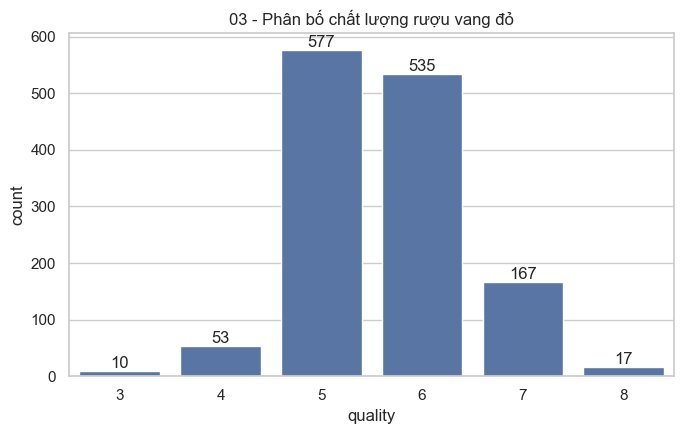

Biến lệch mạnh nhất (|skew|):
chlorides         5.50
residual sugar    4.55
sulphates         2.41
Name: skew, dtype: float64
Biến nhiều ngoại lai nhất (1.5*IQR):
residual sugar    126.0
chlorides          87.0
sulphates          55.0
Name: so_outlier_iqr, dtype: float64
Số cột có mean > median: 10 / 12
Đã cập nhật: results_summary.csv


In [6]:
tk = mo_ta_thong_ke(wine)
display(tk.round(3))
tk.round(4).to_csv(FIG_DIR / '03_wine_descriptive_stats.csv')

phan_bo = wine['quality'].value_counts().sort_index().to_frame('so_luong')
phan_bo['ty_le_pct'] = (phan_bo['so_luong'] / phan_bo['so_luong'].sum() * 100).round(2)
display(phan_bo)

plt.figure(figsize=(7, 4.5))
ax = sns.countplot(data=wine, x='quality')
ax.bar_label(ax.containers[0])
plt.title('03 - Phân bố chất lượng rượu vang đỏ')
luu_hinh('03_wine_quality_distribution')

print('Biến lệch mạnh nhất (|skew|):')
print(tk['skew'].abs().sort_values(ascending=False).head(3).round(2))
print('Biến nhiều ngoại lai nhất (1.5*IQR):')
print(tk['so_outlier_iqr'].sort_values(ascending=False).head(3))
print('Số cột có mean > median:', int((tk['mean'] > tk['median']).sum()), '/', len(tk))
cap_nhat_summary('03_wine_descriptive', 'winequality-red.csv', wine)

## 4. Nhận xét

Các biến có skew dương lớn và nhiều ngoại lai nên trung vị và IQR đáng tin hơn mean và std khi mô tả chúng. `quality` là biến thứ tự tập trung vào vài mức giữa, tức dữ liệu mất cân bằng lớp; cần lưu ý khi dùng làm biến mục tiêu. Ngoại lai được đếm theo quy tắc 1.5*IQR nhưng chưa bị xóa vì có thể là mẫu rượu thực sự khác biệt.